# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [2]:
TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for variable in (x, y, z):
        variable.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]]) for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [3]:
LOW, MEDIUM, HIGH = TERMS

RANGE_SCORE = (0, 10)
RANGE_BUDGET = (0, 200)
RANGE_BOX_OFFICE = (0, 500)

# у README варіанта таблиці всіх трьох підсистем однакові
RULES_DIRECTION = [[LOW, LOW, MEDIUM], [LOW, MEDIUM, HIGH], [MEDIUM, HIGH, HIGH]]
RULES_SPECTACLE = RULES_DIRECTION
RULES_BOX_OFFICE = RULES_DIRECTION


def compute_output(sim, x_value, y_value):
    sim.input["x"] = x_value
    sim.input["y"] = y_value
    sim.compute()
    return float(sim.output["z"])


def box_office(table, method):
    sim = fuzzy_system(RANGE_SCORE, RANGE_SCORE, RANGE_BOX_OFFICE, table, method)
    return compute_output(sim, direction, spectacle)


direction = compute_output(fuzzy_system(RANGE_SCORE, RANGE_SCORE, RANGE_SCORE, RULES_DIRECTION, "centroid"), 8.5, 2.5)
spectacle = compute_output(fuzzy_system(RANGE_BUDGET, RANGE_SCORE, RANGE_SCORE, RULES_SPECTACLE, "centroid"), 100, 9.5)
box_office_centroid = box_office(RULES_BOX_OFFICE, "centroid")
box_office_mom = box_office(RULES_BOX_OFFICE, "mom")

print(f"1.1 якість режисерської роботи: {direction:.3f}")
print(f"1.2 видовищність фільму: {spectacle:.3f}")
print(f"1.3 касові збори, центроїд: {box_office_centroid:.3f}")
print(f"1.3 касові збори, середнє максимумів: {box_office_mom:.3f}")

1.1 якість режисерської роботи: 5.346
1.2 видовищність фільму: 7.382
1.3 касові збори, центроїд: 276.929
1.3 касові збори, середнє максимумів: 250.000


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [4]:
low_end, high_end = RANGE_SCORE
middle = (low_end + high_end) / 2
score_universe = np.linspace(low_end, high_end, 201)
term_shapes = {
    LOW: fuzz.trimf(score_universe, [low_end, low_end, middle]),
    MEDIUM: fuzz.trimf(score_universe, [low_end, middle, high_end]),
    HIGH: fuzz.trimf(score_universe, [middle, high_end, high_end]),
}


def membership(value, term):
    return float(fuzz.interp_membership(score_universe, term_shapes[term], value))


for term in TERMS:
    print(f"{term}: x = {membership(direction, term):.3f}, y = {membership(spectacle, term):.3f}")

rule_strengths = pd.DataFrame([
    {"x": x_term, "y": y_term, "z": RULES_BOX_OFFICE[i][j],
     "сила": min(membership(direction, x_term), membership(spectacle, y_term))}
    for i, x_term in enumerate(TERMS) for j, y_term in enumerate(TERMS)
]).sort_values("сила", ascending=False, ignore_index=True)
print(rule_strengths.round(3))

низький: x = 0.000, y = 0.000
середній: x = 0.931, y = 0.524
високий: x = 0.069, y = 0.476
          x         y         z   сила
0  середній  середній  середній  0.524
1  середній   високий   високий  0.476
2   високий  середній   високий  0.069
3   високий   високий   високий  0.069
4   низький   низький   низький  0.000
5   низький  середній   низький  0.000
6   низький   високий  середній  0.000
7  середній   низький   низький  0.000
8   високий   низький  середній  0.000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

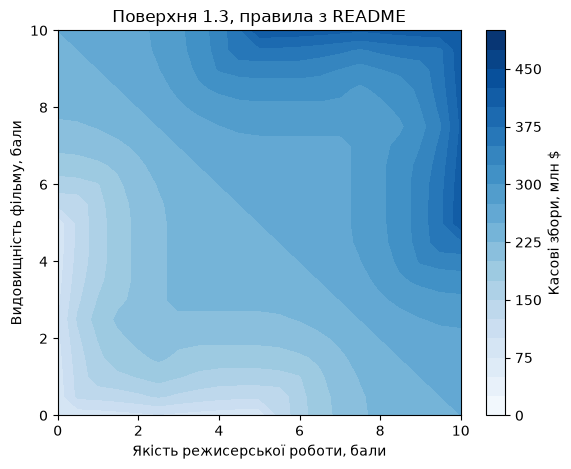

вихід на сітці: від 83.3 до 416.7 млн $


In [5]:
AXIS_VALUES = np.linspace(*RANGE_SCORE, 21)


def surface_1_3(table):
    sim = fuzzy_system(RANGE_SCORE, RANGE_SCORE, RANGE_BOX_OFFICE, table, "centroid")
    return np.array([[compute_output(sim, x_value, y_value) for x_value in AXIS_VALUES] for y_value in AXIS_VALUES])


def draw_surface(axis, values, title, colorbar_label, levels, cmap="Blues"):
    mesh = axis.contourf(AXIS_VALUES, AXIS_VALUES, values, levels=levels, cmap=cmap)
    plt.colorbar(mesh, ax=axis, label=colorbar_label)
    axis.set_xlabel("Якість режисерської роботи, бали")
    axis.set_ylabel("Видовищність фільму, бали")
    axis.set_title(title)


BOX_OFFICE_LEVELS = np.linspace(*RANGE_BOX_OFFICE, 21)
surface_base = surface_1_3(RULES_BOX_OFFICE)

fig, axis = plt.subplots(figsize=(6.5, 5))
draw_surface(axis, surface_base, "Поверхня 1.3, правила з README", "Касові збори, млн $", BOX_OFFICE_LEVELS)
plt.show()
print(f"вихід на сітці: від {surface_base.min():.1f} до {surface_base.max():.1f} млн $")

### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

                      центроїд  середнє максимумів
правила з README       276.929             250.000
зі зміненим правилом   403.853             440.018


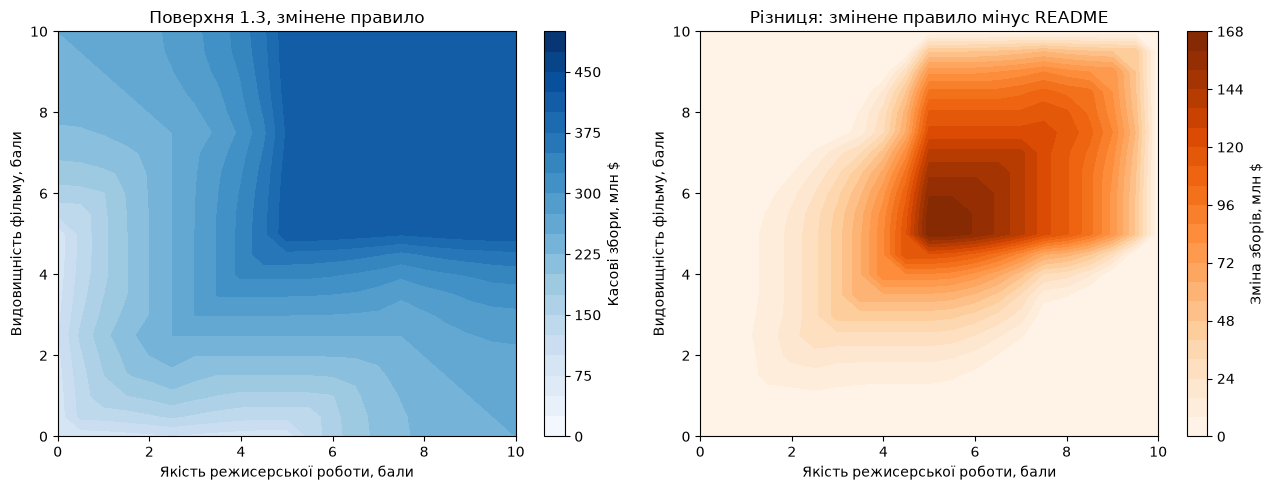

різниця на сітці: від 0.0 до 166.7 млн $
клітинок сітки, де вихід змінився: 271 із 441


In [6]:
RULES_CHANGED = [row[:] for row in RULES_BOX_OFFICE]
RULES_CHANGED[TERMS.index(MEDIUM)][TERMS.index(MEDIUM)] = HIGH

changed_centroid = box_office(RULES_CHANGED, "centroid")
changed_mom = box_office(RULES_CHANGED, "mom")
print(pd.DataFrame(
    {"центроїд": [box_office_centroid, changed_centroid], "середнє максимумів": [box_office_mom, changed_mom]},
    index=["правила з README", "зі зміненим правилом"],
).round(3))

surface_changed = surface_1_3(RULES_CHANGED)
surface_difference = surface_changed - surface_base

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_surface(axes[0], surface_changed, "Поверхня 1.3, змінене правило", "Касові збори, млн $", BOX_OFFICE_LEVELS)
draw_surface(axes[1], surface_difference, "Різниця: змінене правило мінус README", "Зміна зборів, млн $", 20, cmap="Oranges")
plt.tight_layout()
plt.show()

changed_cells = np.abs(surface_difference) > 1e-6
print(f"різниця на сітці: від {surface_difference.min():.1f} до {surface_difference.max():.1f} млн $")
print(f"клітинок сітки, де вихід змінився: {changed_cells.sum()} із {changed_cells.size}")

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [7]:
sample = pd.read_csv("../variants/2/sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
y_min, y_span = y_tr.min(), y_tr.max() - y_tr.min()
x_tr, x_te = (X_tr - x_min) / (x_max - x_min), (X_te - x_min) / (x_max - x_min)
t_tr, t_te = (y_tr - y_min) / y_span, (y_te - y_min) / y_span

mean_rmse_tr, mean_rmse_te = (float(np.sqrt(np.mean((part - y_tr.mean()) ** 2))) for part in (y_tr, y_te))
print("розміри:", X_tr.shape, X_te.shape, "y_span:", round(float(y_span), 3))
print(f"RMSE прогнозу середнім: навчальна {mean_rmse_tr:.4f}, тестова {mean_rmse_te:.4f}")

розміри: (45, 4) (16, 4) y_span: 4.674
RMSE прогнозу середнім: навчальна 1.0168, тестова 0.8919


In [8]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [9]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [10]:
clustering_data = np.column_stack([x_tr, t_tr])
for radius in (0.3, 0.5, 0.8):
    print(f"ra = {radius}: правил {len(subclust(clustering_data, radius))}")

ra = 0.3: правил 28
ra = 0.5: правил 8
ra = 0.8: правил 3


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [11]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum()) for k in range(c)])
    return pack(centers, np.clip(widths, 0.08, 0.8))


theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

print(pd.DataFrame(
    [(mean_rmse_tr, mean_rmse_te), errors(theta, 3), errors(theta_tuned, 3)],
    columns=["навчальна", "тестова"],
    index=["прогноз середнім", "3 правила, до налаштування", "3 правила, після налаштування"],
).round(4))

                               навчальна  тестова
прогноз середнім                  1.0168   0.8919
3 правила, до налаштування        0.7801   0.7935
3 правила, після налаштування     0.4859   1.1185


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

        навчальна  тестова  розрив
правил                            
2          0.6853   0.8424  0.1571
3          0.4859   1.1185  0.6327
4          0.5171   1.0324  0.5153
5          0.3846   0.8090  0.4243
6          0.3022   0.9538  0.6517


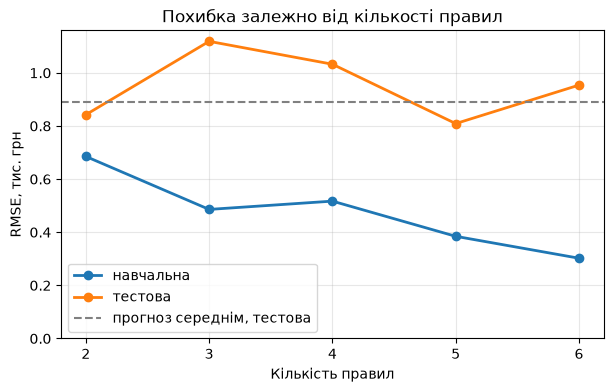

In [12]:
rule_counts = range(2, 7)
rule_count_errors = pd.DataFrame(
    [errors(tune(cmeans_rules(count), count), count) for count in rule_counts],
    columns=["навчальна", "тестова"],
    index=pd.Index(rule_counts, name="правил"),
)
rule_count_errors["розрив"] = rule_count_errors["тестова"] - rule_count_errors["навчальна"]
print(rule_count_errors.round(4))

plt.figure(figsize=(7, 4))
plt.plot(rule_counts, rule_count_errors["навчальна"], "o-", linewidth=2, label="навчальна")
plt.plot(rule_counts, rule_count_errors["тестова"], "o-", linewidth=2, label="тестова")
plt.axhline(mean_rmse_te, color="gray", linestyle="--", label="прогноз середнім, тестова")
plt.xticks(list(rule_counts))
plt.ylim(bottom=0)
plt.xlabel("Кількість правил")
plt.ylabel("RMSE, тис. грн")
plt.title("Похибка залежно від кількості правил")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [13]:
FUND = (8, 5, 5)
TIME_DIV = 8

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample.iloc[:, -1].to_numpy()
print("об'єктів:", len(t), "сумарний час:", round(float(t.sum()), 3), "сумарні втрати:", round(float(v.sum()), 3))

об'єктів: 61 сумарний час: 164.793 сумарні втрати: 120.315


In [14]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [15]:
def show_plan(name, plan):
    print(f"{name}: сума {value(plan):.3f}, завантаження {np.round(load(plan), 3).tolist()}, перевищення {overflow(plan):.3f}")


plan_greedy = np.zeros(len(t), int)
for i in np.argsort(-(v / t)):
    for brigade, (used, fund) in enumerate(zip(load(plan_greedy), FUND), start=1):
        if used + t[i] <= fund:
            plan_greedy[i] = brigade
            break

show_plan("жадібний алгоритм", plan_greedy)

жадібний алгоритм: сума 24.587, завантаження [7.278, 4.402, 4.922], перевищення 0.000


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [16]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
show_plan("ГА з ремонтом", plan_repair)

ГА з ремонтом: сума 25.044, завантаження [7.919, 4.68, 4.765], перевищення 0.000


In [17]:
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
show_plan("ГА зі штрафом", plan_penalty)

ГА зі штрафом: сума 17.566, завантаження [7.035, 5.134, 4.84], перевищення 0.134


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [18]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [19]:
plan_optimum = optimum()

plans = {"жадібний алгоритм": plan_greedy, "ГА з ремонтом": plan_repair, "ГА зі штрафом": plan_penalty, "оптимум": plan_optimum}
pd.set_option("display.width", 200, "display.max_colwidth", 40)
print(pd.DataFrame([
    {"план": name, "сума": round(value(plan), 3), "завантаження": np.round(load(plan), 3).tolist(),
     "перевищення": round(overflow(plan), 3), "% оптимуму": round(100 * value(plan) / value(plan_optimum), 2)}
    for name, plan in plans.items()
]).to_string(index=False))

             план   сума          завантаження  перевищення  % оптимуму
жадібний алгоритм 24.587 [7.278, 4.402, 4.922]        0.000       96.10
    ГА з ремонтом 25.044  [7.919, 4.68, 4.765]        0.000       97.88
    ГА зі штрафом 17.566  [7.035, 5.134, 4.84]        0.134       68.65
          оптимум 25.586  [7.989, 4.68, 4.784]        0.000      100.00


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [20]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 25.044 з оптимуму 25.586
